In [1]:
#Import Statements
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

RANDOM_STATE = 42

N_SPLITS = 5
TEST_SIZE = 252
GAP = 1

BUY_THRESHOLD = 0.55
TRANSACTION_COST = 0.001  # 0.10% per position change

TRADING_DAYS = 252

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.5f}".format)

In [2]:
#Load AAPL Daily Data
DATA_PATH = Path("../data/raw/AAPL_daily_raw.csv")

if not DATA_PATH.exists():
    DATA_PATH = Path("data/raw/AAPL_daily_raw.csv")

df = pd.read_csv(DATA_PATH, index_col=0)

df.index = pd.to_datetime(
    df.index.astype(str).str.slice(0, 19),
    errors="raise"
)

df = df.sort_index()
df.index.name = "Date"

print("Rows:", len(df))
print("Date range:", df.index.min(), "to", df.index.max())

Rows: 2766
Date range: 2015-01-02 00:00:00 to 2025-12-31 00:00:00


In [3]:
#Build Features and Target
data = df.copy()

data["return_1d"] = data["Adj Close"].pct_change(1)
data["return_5d"] = data["Adj Close"].pct_change(5)
data["return_10d"] = data["Adj Close"].pct_change(10)

data["price_to_sma20"] = (
    data["Adj Close"] / data["Adj Close"].rolling(20).mean() - 1
)

data["price_to_sma50"] = (
    data["Adj Close"] / data["Adj Close"].rolling(50).mean() - 1
)

data["volatility_20d"] = data["return_1d"].rolling(20).std()

data["momentum_10d"] = (
    data["Adj Close"] / data["Adj Close"].shift(10) - 1
)

data["relative_volume"] = (
    data["Volume"] / data["Volume"].rolling(20).mean()
)

# Next trading day's close-to-close return
data["future_return_1d"] = (
    data["Adj Close"].shift(-1) / data["Adj Close"] - 1
)

data["target_up"] = (
    data["future_return_1d"] > 0
).astype(int)

feature_cols = [
    "return_1d",
    "return_5d",
    "return_10d",
    "price_to_sma20",
    "price_to_sma50",
    "volatility_20d",
    "momentum_10d",
    "relative_volume"
]

model_df = data[
    feature_cols + ["target_up", "future_return_1d"]
].dropna()

X = model_df[feature_cols]
y = model_df["target_up"]

print("Feature shape:", X.shape)
print("Target distribution:")
print(y.value_counts(normalize=True))

Feature shape: (2716, 8)
Target distribution:
target_up
1   0.52946
0   0.47054
Name: proportion, dtype: float64


In [4]:
#Defining the model pipeline
model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        C=0.1,
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",0.1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",2000


In [5]:
#Expanding window cross-validation with a gap of 1 day between train and test sets
splitter = TimeSeriesSplit(
    n_splits=N_SPLITS,
    test_size=TEST_SIZE,
    gap=GAP
)

prediction_records = []

for fold, (train_idx, val_idx) in enumerate(
    splitter.split(X), start=1
):

    X_train = X.iloc[train_idx]
    X_val = X.iloc[val_idx]

    y_train = y.iloc[train_idx]

    fold_model = Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            C=0.1,
            max_iter=2000,
            class_weight="balanced",
            random_state=RANDOM_STATE
        ))
    ])

    fold_model.fit(X_train, y_train)

    probabilities = fold_model.predict_proba(X_val)[:, 1]

    fold_predictions = pd.DataFrame({
        "fold": fold,
        "probability_up": probabilities
    }, index=X_val.index)

    prediction_records.append(fold_predictions)

predictions_df = pd.concat(prediction_records).sort_index()

print("Out-of-sample predictions:", len(predictions_df))
print(predictions_df.head())
print(predictions_df.tail())

Out-of-sample predictions: 1260
            fold  probability_up
Date                            
2020-12-23     1         0.54219
2020-12-24     1         0.51443
2020-12-28     1         0.46731
2020-12-29     1         0.56273
2020-12-30     1         0.54926
            fold  probability_up
Date                            
2025-12-23     5         0.49589
2025-12-24     5         0.50072
2025-12-26     5         0.50761
2025-12-29     5         0.50454
2025-12-30     5         0.50949


In [6]:
#Builiding the preditction ledger
ledger = predictions_df.copy()

ledger["actual_return"] = model_df.loc[
    ledger.index, "future_return_1d"
]

ledger["actual_direction"] = model_df.loc[
    ledger.index, "target_up"
]

ledger["predicted_signal"] = np.where(
    ledger["probability_up"] >= BUY_THRESHOLD,
    1,
    0
)

ledger.head(10)

,fold,probability_up,actual_return,actual_direction,predicted_signal
Date,,,,,
2020-12-23,1,0.54219,0.00771,1,0
2020-12-24,1,0.51443,0.03577,1,0
2020-12-28,1,0.46731,-0.01331,0,0
2020-12-29,1,0.56273,-0.00853,0,1
2020-12-30,1,0.54926,-0.00770,0,0
2020-12-31,1,0.54163,-0.02472,0,0
2021-01-04,1,0.55758,0.01236,1,1
2021-01-05,1,0.46608,-0.03366,0,0
2021-01-06,1,0.55284,0.03412,1,1


In [7]:
#Converting Singals into positions
ledger["position"] = (
    ledger["predicted_signal"].shift(1).fillna(0)
)

ledger[[
    "probability_up",
    "predicted_signal",
    "position",
    "actual_return"
]].head(10)

,probability_up,predicted_signal,position,actual_return
Date,,,,
2020-12-23,0.54219,0,0.00000,0.00771
2020-12-24,0.51443,0,0.00000,0.03577
2020-12-28,0.46731,0,0.00000,-0.01331
2020-12-29,0.56273,1,0.00000,-0.00853
2020-12-30,0.54926,0,1.00000,-0.00770
2020-12-31,0.54163,0,0.00000,-0.02472
2021-01-04,0.55758,1,0.00000,0.01236
2021-01-05,0.46608,0,1.00000,-0.03366
2021-01-06,0.55284,1,0.00000,0.03412


In [8]:
#Calculating the gross and net strategy returns
ledger["gross_strategy_return"] = (
    ledger["position"] * ledger["actual_return"]
)

# How much did the position change?
ledger["previous_position"] = (
    ledger["position"].shift(1).fillna(0)
)

ledger["turnover"] = (
    ledger["position"] - ledger["previous_position"]
).abs()

# Charge transaction cost whenever the position changes
ledger["transaction_cost"] = (
    ledger["turnover"] * TRANSACTION_COST
)

ledger["net_strategy_return"] = (
    ledger["gross_strategy_return"]
    - ledger["transaction_cost"]
)

ledger[[
    "position",
    "actual_return",
    "gross_strategy_return",
    "turnover",
    "transaction_cost",
    "net_strategy_return"
]].head(10)

,position,actual_return,gross_strategy_return,turnover,transaction_cost,net_strategy_return
Date,,,,,,
2020-12-23,0.00000,0.00771,0.00000,0.00000,0.00000,0.00000
2020-12-24,0.00000,0.03577,0.00000,0.00000,0.00000,0.00000
2020-12-28,0.00000,-0.01331,-0.00000,0.00000,0.00000,-0.00000
2020-12-29,0.00000,-0.00853,-0.00000,0.00000,0.00000,-0.00000
2020-12-30,1.00000,-0.00770,-0.00770,1.00000,0.00100,-0.00870
2020-12-31,0.00000,-0.02472,-0.00000,1.00000,0.00100,-0.00100
2021-01-04,0.00000,0.01236,0.00000,0.00000,0.00000,0.00000
2021-01-05,1.00000,-0.03366,-0.03366,1.00000,0.00100,-0.03466
2021-01-06,0.00000,0.03412,0.00000,1.00000,0.00100,-0.00100


In [9]:
#Creating the strategy and buy-and-hold equity curves
ledger["buy_hold_return"] = ledger["actual_return"]

ledger["strategy_equity"] = (
    1 + ledger["net_strategy_return"]
).cumprod()

ledger["buy_hold_equity"] = (
    1 + ledger["buy_hold_return"]
).cumprod()

ledger[[
    "strategy_equity",
    "buy_hold_equity"
]].tail()

,strategy_equity,buy_hold_equity
Date,,
2025-12-23,0.86651,2.14781
2025-12-24,0.86651,2.14459
2025-12-26,0.86651,2.14742
2025-12-29,0.86651,2.14208
2025-12-30,0.86651,2.13251


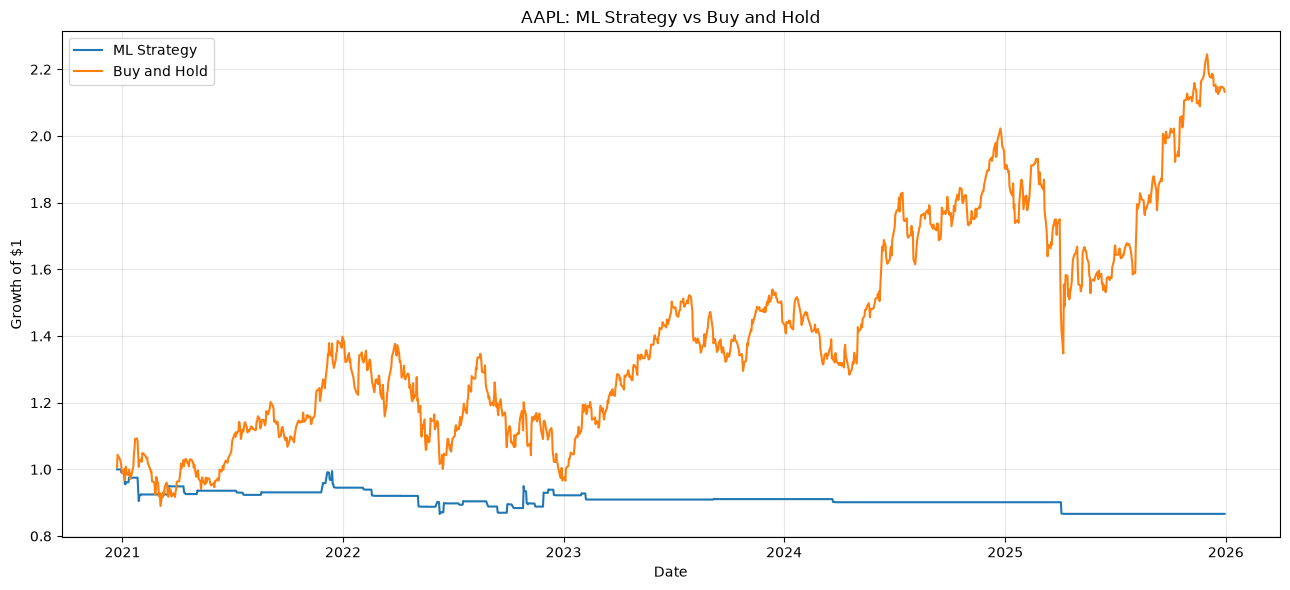

In [10]:
plt.figure(figsize=(13, 6))

plt.plot(
    ledger.index,
    ledger["strategy_equity"],
    label="ML Strategy"
)

plt.plot(
    ledger.index,
    ledger["buy_hold_equity"],
    label="Buy and Hold"
)

plt.title("AAPL: ML Strategy vs Buy and Hold")
plt.xlabel("Date")
plt.ylabel("Growth of $1")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [11]:
# Calculate performance metrics for a strategy
def calculate_metrics(returns):

    returns = returns.dropna()

    equity = (1 + returns).cumprod()

    total_return = equity.iloc[-1] - 1

    years = len(returns) / TRADING_DAYS

    annualized_return = (
        equity.iloc[-1] ** (1 / years) - 1
    )

    annualized_volatility = (
        returns.std() * np.sqrt(TRADING_DAYS)
    )

    sharpe_ratio = (
        returns.mean() / returns.std()
    ) * np.sqrt(TRADING_DAYS)

    running_peak = equity.cummax()

    drawdown = equity / running_peak - 1

    max_drawdown = drawdown.min()

    return {
        "total_return": total_return,
        "annualized_return": annualized_return,
        "annualized_volatility": annualized_volatility,
        "sharpe_ratio": sharpe_ratio,
        "max_drawdown": max_drawdown
    }

In [12]:
#Comparing the performance of the ML strategy and buy-and-hold
strategy_metrics = calculate_metrics(
    ledger["net_strategy_return"]
)

buy_hold_metrics = calculate_metrics(
    ledger["buy_hold_return"]
)

comparison = pd.DataFrame({
    "ML Strategy": strategy_metrics,
    "Buy and Hold": buy_hold_metrics
})

comparison

,ML Strategy,Buy and Hold
total_return,-0.13349,1.13251
annualized_return,-0.02825,0.16353
annualized_volatility,0.07646,0.27878
sharpe_ratio,-0.33673,0.68207
max_drawdown,-0.13379,-0.33361


In [13]:
#Inspect Trade Statistics
number_of_entries = (
    (ledger["position"] == 1) &
    (ledger["previous_position"] == 0)
).sum()

number_of_exits = (
    (ledger["position"] == 0) &
    (ledger["previous_position"] == 1)
).sum()

exposure = ledger["position"].mean()

print("Entries:", number_of_entries)
print("Exits:", number_of_exits)
print("Total position changes:", ledger["turnover"].sum())
print("Market exposure:", f"{exposure:.2%}")
print("Transaction cost:", f"{ledger['transaction_cost'].sum():.4f}")

Entries: 43
Exits: 43
Total position changes: 86.0
Market exposure: 3.97%
Transaction cost: 0.0860


In [14]:
assert ledger.index.is_monotonic_increasing
assert ledger.index.is_unique

assert ledger["position"].isin([0, 1]).all()

assert (
    ledger["transaction_cost"] >= 0
).all()

assert np.isfinite(
    ledger["net_strategy_return"].to_numpy()
).all()

assert np.isfinite(
    ledger["strategy_equity"].to_numpy()
).all()

print("Backtesting integrity checks passed.")

Backtesting integrity checks passed.


In [15]:
OUTPUT_DIR = Path("../data/processed")

if not OUTPUT_DIR.exists():
    OUTPUT_DIR = Path("data/processed")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

ledger.to_csv(
    OUTPUT_DIR / "week6_day1_backtest_ledger.csv"
)

comparison.to_csv(
    OUTPUT_DIR / "week6_day1_strategy_comparison.csv"
)

print("Saved outputs to:", OUTPUT_DIR.resolve())

Saved outputs to: C:\Users\padam\stock-prediction-lab\notebooks\data\processed
